# 02 · 课程查询、新增课程与前后端联调


## 资料来源与当天目标

本篇对应 14 天规划的 **day02 课程查询 新增课程 前后端联调**，承接第一篇的环境与 parent / base 工程。当天要打通四个接口：课程列表、数据字典、课程分类树、新增课程。

| 资料 | 定位与本篇使用范围 |
|---|---|
| 《第2章 内容管理模块v3.1.docx》 | `day02/资料`；百度预览 174 页；本篇使用第 1—4 节、第 5 节至 5.6“异常处理” |
| `xuecheng-plus-project.zip` | `day02/代码`；静态读取 11 个 POM、content / system 模块、公共模型、异常处理和 HTTP 请求文件 |
| 当天辅助文件 | `AddCourseDto.java`、`CourseBaseInfoDto.java`、`CommonError.java`、`GlobalCorsConfig.java`、`xuecheng-plus-system.zip`；目录已核对，本篇以代码包内对应类为实现依据 |
| [网盘分享](https://pan.baidu.com/s/16iXzw7cFDk3FqG9DfPqbdg?pwd=6633) | 提取码 `6633`；Java 项目《学成在线》企业级开发实战 → 学成在线项目—资料 |
| [在线讲义入口](https://mx67xggunk5.feishu.cn/wiki/Y39iwM0mJidfeWkDmKJcp8uPn4f) | 原文件与第一篇属于同一项目；本篇以下载的 v3.1 讲义及 day02 代码为准 |

**学习路径**：需求与分层 → 接口契约 → MyBatis-Plus 分页 → 字典与前端联调 → 分类树 → 新增课程与事务 → 统一异常处理。

第 5.7 节 JSR303、修改课程与课程计划随 day03 展开，项目实战随 day04 展开。第二章跨多天，不能将 174 页全部当成 day02。

> 约定：原资料事实与“补充 / 校正”明确区分。Java 示例是课程核心片段或注明的补全片段，配置中的地址和账号要按自己的环境填写；未编译、启动或操作课程数据库。原图已嵌入 Notebook，可离线阅读。


## 1. 需求分析：把“添加课程”变成可实现的规则

“老师把课程放到网上”不足以直接写代码，还要知道输入、权限、结果和失败分支。

**需求分析**把用户的原始描述转为系统必须完成的功能和约束。讲义的步骤是：确认用户需求 → 找关键问题 → 梳理业务流程 → 数据建模 → 编写需求规格说明书。

| 添加课程用例 | 需要明确的内容 |
|---|---|
| 参与者 | 教学机构管理员 / 老师 |
| 前置条件 | 已登录，具有添加权限，只能向自己机构添加课程 |
| 输入 | 基本信息、分类、营销信息等 |
| 基本流程 | 课程列表 → 添加 → 选择形式 → 填表 → 保存 |
| 成功结果 | 写入基本信息和营销信息，取得课程 ID，进入后续编辑 |
| 失败结果 | 返回明确错误，不能留下半份课程 |
| 后置状态 | 未提交审核 / 未审核，未发布 |

**怎么用**：先从原型列出表单字段，再区分用户填写、系统生成和身份上下文提供的值。例如课程名来自表单，创建时间来自后端，机构 ID 应来自登录身份；前端显示“添加成功”不能代替检查数据库写入结果。


## 2. 内容管理的数据模型

一门课程有基本信息、营销、目录、师资和发布信息，放在一张大表里会混淆不同阶段的数据。

**内容管理**维护可编辑、可审核、可发布的课程内容。讲义列出 9 张基础表：

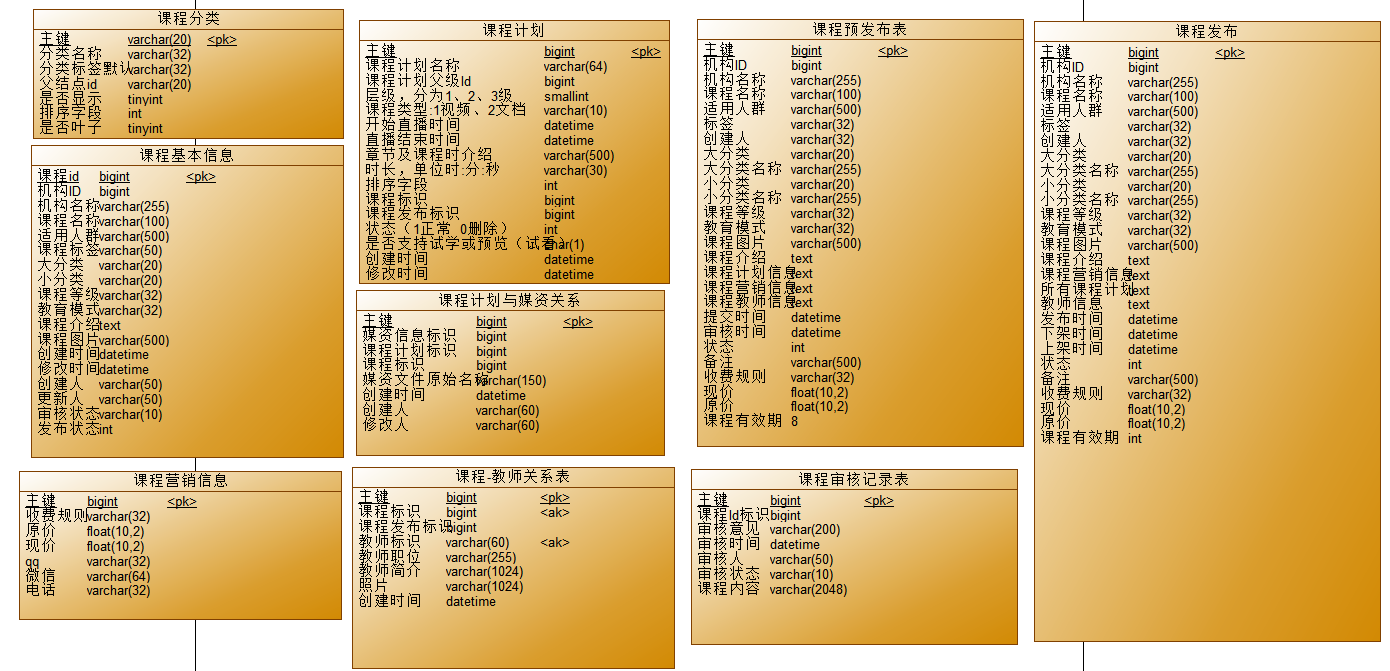

原图来源：第二章“1.5 数据模型”。图是整体设计示意；字段类型以实际数据库与当前 PO 为准。

| 表 / 数据 | 责任 | 本篇关系 |
|---|---|---|
| `course_base` | 课程基本信息、机构、审核和发布状态 | 列表查询与新增的主表 |
| `course_market` | 收费规则、价格、咨询方式等 | 新增时与主表一对一保存 |
| `course_category` | 大类、小类及父子关系 | 查询分类树，供新增页面选择 |
| `teachplan` | 课程章节与小节 | day03 |
| `teachplan_media` | 课程计划与媒资关联 | 后续计划 / 媒资业务 |
| `course_teacher` | 课程师资 | 后续实战 |
| `course_publish_pre` | 待审核的课程信息快照 | 后续审核与发布 |
| `course_publish` | 已发布的课程信息 | day08 |
| `course_audit` | 审核记录 | 后续审核业务 |

`course_market.id`在课程实现中使用`course_base.id`，把两部分信息定位到同一门课程。这里的关联由代码维护，是否还建外键约束应看实际 SQL，不能仅凭模型图认定存在外键。


## 3. content 工程与 Controller、Service、Mapper

HTTP 参数处理、业务规则和数据库操作职责不同，分层便于替换、测试和协作。

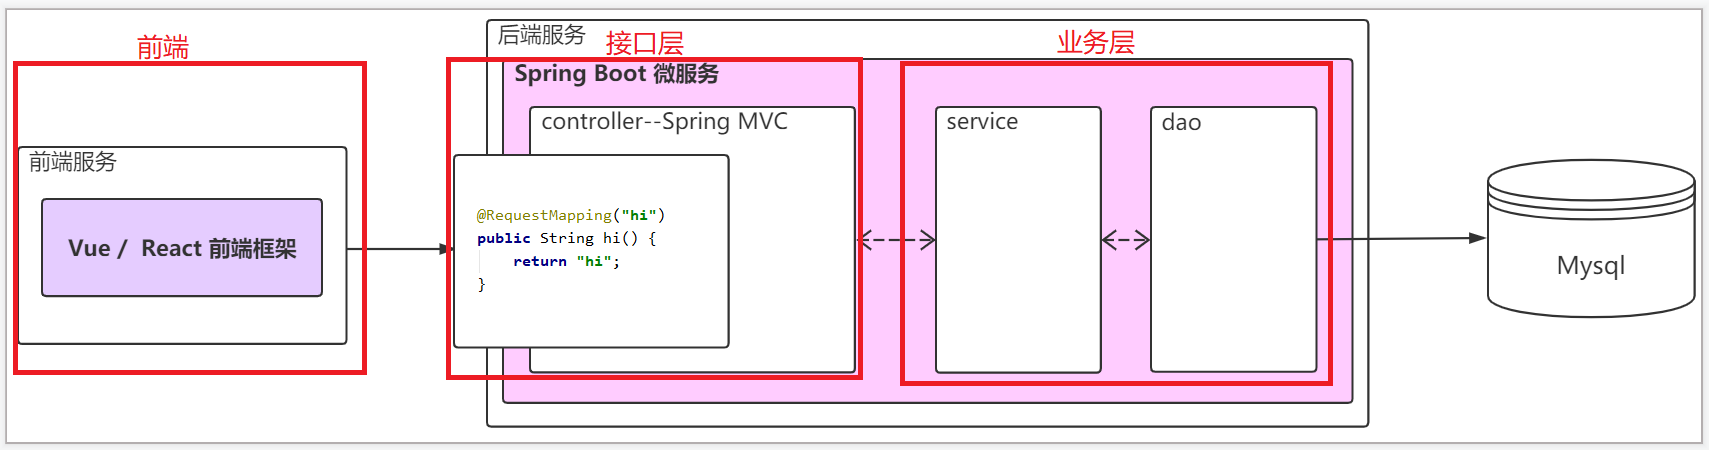

原图来源：第二章“2.1 模块工程结构”。

| 工程 / 层 | 主要内容 | 依赖关系 |
|---|---|---|
| `xuecheng-plus-content` | 内容模块父 POM、聚合工程 | 继承项目 parent，聚合下面三个模块 |
| `content-api` | Controller、应用启动与 HTTP 配置 | 依赖 service |
| `content-service` | Service、Mapper、SQL、事务 | 依赖 model |
| `content-model` | DTO、PO 等模型类 | 依赖 base |
| `xuecheng-plus-base` | 通用分页、日期转换、异常模型 | 继承项目 parent |

`浏览器 → Controller → Service → Mapper → MySQL → 返回 JSON`

**Controller**负责请求绑定与调用业务；**Service**负责条件、状态、事务等业务规则；**Mapper / DAO**负责数据访问。本项目把 Service 和 DAO 放进同一工程，不表示它们是同一职责。

`content`的`packaging`为`pom`，`modules`包含 api、model、service；三个子模块都继承 content。聚合关系和 JAR 依赖关系分别声明，不能因为一个模块出现在`modules`中，就自动在其他模块中使用它的类。


## 4. 应用配置、数据库和访问地址

能启动应用却请求 404，常见原因是端口、上下文路径和 Controller 路径没有拼对。

| 应用 | 课程地址 | 用途 |
|---|---|---|
| 前端开发服务 | `http://localhost:8601` | 教学管理页面 |
| 内容管理服务 | `http://localhost:63040/content` | 课程与分类接口 |
| 系统管理服务 | `http://localhost:63110/system` | 数据字典 |
| 网关 | 资料中预留 63010 | day02 尚未搭建，后续接入 |

内容服务配置示例（连接参数用环境变量表示）：

```yaml
server:
  port: 63040
  servlet:
    context-path: /content
spring:
  application:
    name: content-api
  datasource:
    driver-class-name: com.mysql.cj.jdbc.Driver
    url: "jdbc:mysql://${DB_HOST:127.0.0.1}:${DB_PORT:3306}/${DB_NAME:xc402_content}?serverTimezone=UTC&useUnicode=true&characterEncoding=UTF-8"
    username: ${DB_USER}
    password: ${DB_PASSWORD}
logging:
  config: classpath:log4j2-dev.xml
```

**补充 / 校正**：day02 代码连接`xc402_content`、`xc402_system`；讲义文字和截图另有`xcplus_content`、`xc166_content`等名称。以自己导入的库为准，同步修改运行配置、测试配置和生成器配置。SQL 文件叫`xc_content.sql`，不代表数据库必须叫同名。

原 JDBC URL 把`useUnicode`写成`userUnicode`，且末尾多一个`&`；示例修正拼写并移除多余分隔符。`serverTimezone`是 JDBC 连接选项，不会自动把所有`LocalDateTime`改为带时区时间。

完整路径为`端口 + context-path + Controller 映射`，例如`63040/content/course/list`。不能在 Controller 和配置中重复加`/content`。


## 5. PO、代码生成器与模型放置

表字段多时手写映射容易出错，生成器可生成基础文件，业务规则仍要自己确认。

**PO**（Persistent Object，持久化对象）对应表记录。课程使用 MyBatis-Plus Generator 生成 PO、Mapper 接口、XML 和样例代码。

| 生成结果 | 放置位置 | 需要复核 |
|---|---|---|
| PO | model 的`model.po`包 | 表名、字段类型、主键策略、Lombok / MyBatis-Plus 注解 |
| Mapper 接口 | service 的`mapper`包 | 泛型实体、方法名、参数 |
| Mapper XML | 课程放在 Java 的 mapper 目录 | namespace、statement ID、资源是否被打包 |
| 生成的 Controller / Service | 只是模板 | 不能直接代替业务接口和规则实现 |

生成前核对数据库地址、账号、表名、输出路径；输出到临时位置再拷贝需要的文件，避免覆盖手写代码。当天用`ContentCodeGenerator`，本笔记未运行生成器。

model 需要`mybatis-plus-annotation`、`mybatis-plus-core`（3.4.1）及 Lombok；否则 PO 中的框架注解会无法解析。service 需要 MyBatis-Plus Starter、MySQL Driver 和测试依赖。

**怎么用**：生成基础映射后，先以一条`selectById`确认表、列、主键可正确映射，再实现复杂业务。新增课程依赖`CourseBase`主键`IdType.AUTO`，插入后应把生成 ID 回填到对象。


## 6. 课程查询的接口契约

前后端各自开发时，需要对 HTTP 方法、参数位置、字段名和返回结构达成一致。

**接口契约**是双方对调用方式和结果的约定，包含正常及失败分支。课程列表使用 POST 提交业务筛选条件，同时把分页参数放在 URL：

```http
POST http://localhost:63040/content/course/list?pageNo=1&pageSize=10
Content-Type: application/json

{
  "courseName": "java",
  "auditStatus": "",
  "publishStatus": ""
}
```

| 项目 | 课程约定 |
|---|---|
| HTTP 方法 | POST；这是课程的查询接口设计 |
| URL 参数 | `pageNo`、`pageSize` |
| JSON body | `courseName`、`auditStatus`、`publishStatus` |
| 响应 | `PageResult<CourseBase>` |
| 分页字段 | `items`、`counts`、`page`、`pageSize` |
| 状态字段 | 业务代码，前端通过字典映射显示名称 |

响应格式示意（只展示一条记录及部分字段）：

```json
{
  "items": [
    {"id": 26, "name": "Java 课程", "auditStatus": "202002", "status": "203001"}
  ],
  "counts": 23,
  "page": 1,
  "pageSize": 10
}
```

`counts`是满足条件的总记录数，`items.size()`只是本页条数。原型包含“任务数”等列，但原代码直接返回`CourseBase`，并没有自动统计课程计划数；需要的字段应由后续明确实现，不能根据页面列名认定接口已经支持。


## 7. URL 参数、@RequestBody 与空请求体

分页值和筛选条件处于两个位置，注解配置不对会造成参数为空或请求失败。

| 参数 | Spring MVC 如何绑定 | 例子 |
|---|---|---|
| `PageParams` | 未标注`@RequestBody`的复杂对象按模型属性绑定查询参数 | `?pageNo=2&pageSize=5` |
| `QueryCourseParamsDto` | `@RequestBody`读取 JSON，再转为 Java 对象 | `{"courseName":"java"}` |
| 路径参数 | `@PathVariable`读取路径片段 | 后续的`/course/{id}` |

代码包允许查询 body 缺省，但 Service 直接读取其属性，会出现空指针。补全后的 Controller 核心片段：

```java
@PostMapping("/course/list")
public PageResult<CourseBase> list(
        PageParams pageParams,
        @RequestBody(required = false) QueryCourseParamsDto query) {
    QueryCourseParamsDto actual =
            query == null ? new QueryCourseParamsDto() : query;
    return courseBaseInfoService.queryCourseBaseList(pageParams, actual);
}
```

**正例**：发送 POST、`Content-Type: application/json`和`{}`，表示没有业务筛选。  
**反例**：允许 body 缺省，却不处理传入 Service 的`null`。

**补充 / 校正**：浏览器地址栏发 GET。早期`@RequestMapping`可进入不同方法并因缺少 body 报 400；改为`@PostMapping`后，用 GET 请求通常是 **405**。400 是请求内容 / 绑定错误，域名解析失败不是 HTTP 400。

两种设计都可以：明确 body 必填，让前端总发`{}`；或允许缺省并在边界处补默认对象。只能选一套与文档一致的约定。


## 8. DTO、PO、VO 与分页泛型

表字段、请求字段和页面字段并不总是一致，应按数据用途选择模型。

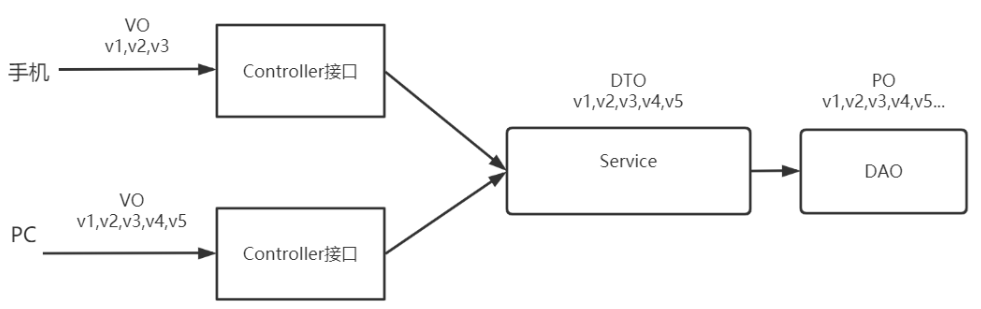

原图来源：第二章“3.3.4 模型类的作用”。

| 模型 | 用途 | 本项目例子 |
|---|---|---|
| PO | 映射数据库持久化数据 | `CourseBase`、`CourseMarket` |
| DTO | 跨接口 / 业务边界传递所需数据 | `QueryCourseParamsDto`、`AddCourseDto`、`CourseBaseInfoDto` |
| VO | 针对展示或特定客户端组织数据 | PC 与手机字段不一致时可以分别设计 |
| PageParams | 通用分页输入 | 默认`pageNo=1`、`pageSize=10` |
| PageResult<T> | 通用分页结果 | `PageResult<CourseBase>` |

**泛型 T**让同一分页外壳承载不同数据项；查询课程时 T 是`CourseBase`。返回字段为`page`，输入字段为`pageNo`，两者名字不同是课程契约，应原样对应。

DTO / VO 是设计角色，实际团队命名可能不同；不是每个接口都必须拥有三套几乎相同的类。多个前端需求相近时，共用业务服务并分别组装返回结构即可。

**补充**：课程列表直接返回 PO 便于教学。若页面只应看到少量字段或存在内部字段，应定义专用返回 DTO / VO，而不是把数据库实体所有属性直接暴露。


## 9. Swagger：描述接口与在线调试

前端需要可读的参数说明，Swagger 根据 Controller 和模型注解生成在线接口文档。

课程使用`com.spring4all:swagger-spring-boot-starter:1.9.0.RELEASE`，配合启动类`@EnableSwagger2Doc`。内容服务配置：

```yaml
swagger:
  title: 学成在线内容管理系统
  description: 课程信息管理
  base-package: com.xuecheng.content
  enabled: true
  version: 1.0.0
```

访问`http://localhost:63040/content/swagger-ui.html`，检查接口方法、分页参数与 JSON body 的描述。

| 常用注解 | 描述什么 |
|---|---|
| `@Api` | Controller 分组 / 标签 |
| `@ApiOperation` | 一个接口方法 |
| `@ApiModel`、`@ApiModelProperty` | 模型与字段 |
| `@ApiParam` | 方法参数说明 |
| `@ApiImplicitParam(s)` | 显式补充参数描述，如位置、类型、必填、默认值 |
| `@ApiResponse(s)` | 响应描述 |
| `@ApiIgnore` | 忽略某个文档元素，属于相应文档工具注解体系 |

`paramType`表示 path、query、body、header 等参数位置；`dataType`描述类型。**文档描述不执行业务校验**：`@ApiModelProperty(required=true)`不等于运行时必填约束。

**校正**：请求 body 不只限于 POST，PUT 等方法也可以有 body；文档中的方法列表应以实际映射注解为准。原表另列`@ApiError`，它不应作为该套常用 Swagger 注解直接照抄。JSR303 的约束及触发方式在 day03 讲。


## 10. LocalDateTime 的 JSON 格式

Java 8 日期时间默认 JSON 表现可能不符合页面约定，需要统一序列化和反序列化。

**序列化**把 Java 值转换为 JSON；**反序列化**把 JSON 转回 Java 值。base 的`LocalDateTimeConfig`使用 Jackson 的 JSR310 支持，注册：

```java
DateTimeFormatter formatter =
        DateTimeFormatter.ofPattern("yyyy-MM-dd HH:mm:ss");
LocalDateTimeSerializer serializer =
        new LocalDateTimeSerializer(formatter);
LocalDateTimeDeserializer deserializer =
        new LocalDateTimeDeserializer(formatter);
```

原实现通过`Jackson2ObjectMapperBuilderCustomizer`按`LocalDateTime.class`注册二者，让时间返回为`"2022-09-08 07:35:16"`，也可接收同格式字符串。

**怎么用**：确认 base 在应用依赖中、配置类被 Spring 扫描、Jackson 的 JSR310 模块可用。启动类在`com.xuecheng`，默认扫描其子包；若以后移动到更窄包，base 配置及异常处理器可能需要显式导入。

> `LocalDateTime`本身不携带时区。统一字符串格式不等于统一时区；记录跨时区时间时还要约定时间语义。JSR310 是日期时间 API，JSR303 是参数校验规范。


## 11. Mapper 扫描与 XML 资源

Mapper 是接口，必须被框架生成代理对象并找到对应 SQL，Spring 才能注入和调用。

课程`MybatisPlusConfig`配置`@MapperScan("com.xuecheng.content.mapper")`。例如`CourseBaseMapper extends BaseMapper<CourseBase>`可直接使用`selectById`、`insert`等通用方法；自定义分类查询再编写 XML。

| 配置 / 文件 | 核对点 |
|---|---|
| Mapper 接口 | 包名处于扫描范围 |
| XML `namespace` | 等于接口完整类名 |
| SQL statement `id` | 等于对应方法名 |
| SQL 参数 | 绑定名称一致；多参数可用`@Param`明确命名 |
| XML 的位置 | 课程放在`src/main/java/.../mapper` |
| 资源处理 | parent 将 Java 目录下`**/*.xml`复制到输出目录 |

自定义 SQL 用`#{id}`绑定值，避免将用户内容直接拼成 SQL。生成的基本 CRUD 不强制要求每个方法都写 XML；“有一个表就要写一套 XML SQL”不是 MyBatis-Plus 的规则。

**怎么用**：Mapper 注入失败先看扫描；`Invalid bound statement`再看 namespace、方法名及 XML 是否进入 classpath。这些问题与 Controller URL 是否正确属于不同层。


## 12. MyBatis-Plus 3.4.1 的分页插件

仅创建`Page`对象不足以保证 SQL 分页，需要分页拦截器参与执行。

课程使用 **3.4.1** 的配置：

```java
@Configuration
@MapperScan("com.xuecheng.content.mapper")
public class MybatisPlusConfig {
    @Bean
    public MybatisPlusInterceptor mybatisPlusInterceptor() {
        MybatisPlusInterceptor interceptor = new MybatisPlusInterceptor();
        interceptor.addInnerInterceptor(
                new PaginationInnerInterceptor(DbType.MYSQL));
        return interceptor;
    }
}
```

| 步骤 | 作用 |
|---|---|
| `new Page<>(pageNo, pageSize)` | 构造 IPage 分页参数 |
| `selectPage(page, wrapper)` | 向 Mapper 传入分页与条件 |
| PaginationInnerInterceptor | 识别分页参数，根据数据库改写分页 SQL，并按配置执行 count |
| `getRecords() / getTotal()` | 取得本页数据与总条数 |
| 构造 PageResult | 转为课程约定的响应外壳 |

MySQL 的核心效果类似`LIMIT offset, size`，`offset=(pageNo-1)×pageSize`。例如第 3 页、每页 10 条，跳过 20 条，最多返回 10 条；总数 23 时最后一页只有 3 条。

**校正原讲义**：此版本 MyBatis-Plus 从 Mapper 方法参数中的`IPage`对象取得分页信息，不应套用“先把分页参数放进 ThreadLocal”的其他分页方案解释。count SQL 也会由插件按配置生成 / 优化，不能保证每种查询都只是机械添加`count(*)`。

实际接口还应限制`pageNo>=1`、合理`pageSize`，并指定稳定排序；默认值不等于合法性校验。


## 13. 动态筛选、机构隔离与稳定分页

查询参数为空时不应生成错误条件；翻页时应使用稳定排序；教学机构查询要考虑数据归属。

原 Service 实现按名称模糊查询、审核状态等值查询，发布状态留 TODO。以下是**补全查询条件的核心片段**：

```java
QueryCourseParamsDto actual =
        query == null ? new QueryCourseParamsDto() : query;
LambdaQueryWrapper<CourseBase> wrapper = new LambdaQueryWrapper<>();
wrapper.like(StringUtils.isNotBlank(actual.getCourseName()),
        CourseBase::getName, actual.getCourseName());
wrapper.eq(StringUtils.isNotBlank(actual.getAuditStatus()),
        CourseBase::getAuditStatus, actual.getAuditStatus());
wrapper.eq(StringUtils.isNotBlank(actual.getPublishStatus()),
        CourseBase::getStatus, actual.getPublishStatus());
wrapper.orderByDesc(CourseBase::getCreateDate)
       .orderByDesc(CourseBase::getId);

Page<CourseBase> page =
        new Page<>(pageParams.getPageNo(), pageParams.getPageSize());
Page<CourseBase> result = courseBaseMapper.selectPage(page, wrapper);
return new PageResult<>(result.getRecords(), result.getTotal(),
        pageParams.getPageNo(), pageParams.getPageSize());
```

`like(condition, getter, value)`只有 condition 为真时才加入条件；`CourseBase::getName`是方法引用，让框架定位实体字段。`isNotBlank`还排除仅空格内容，原实现`isNotEmpty`只排除 null 与空串。

**机构隔离补充**：原方法没有机构参数，也没按`company_id`过滤。完善机构端查询时应从可信身份取得机构 ID，并添加固定过滤条件；必要时调整 Service 签名。不能让用户提交任意机构 ID 作为授权依据。

> 正例：用户筛选条件与机构条件一起作用，按时间再按 ID 排序。反例：接收`publishStatus`却始终忽略，或翻页时不排序。稳定排序可减少相同时间记录的顺序波动；并发新增 / 删除时，offset 分页仍可能出现页间变化。

两种常见查询：无筛选返回本机构课程；组合名称、审核、发布条件时返回三者同时满足的课程。


## 14. 数据字典：业务代码与显示文字分开

“审核未通过”改成“未通过”时，不应更新每门课程的业务记录。

**数据字典**维护相对固定的代码与说明，例如审核状态、课程等级、收费规则。课程表存代码，页面依据字典显示名称。

| 项目 | 原资料值 / 注意点 |
|---|---|
| 审核状态片段 | `202001`审核未通过、`202002`未审核、`202003`审核通过 |
| 新增课程审核初始值 | `202002`，新增小节文字称“未提交” |
| 发布状态初始值 | `203001`未发布 |
| 收费规则 | `201000`免费，`201001`收费 |
| 部分请求样例 | 使用`202004`，与上述三项字典片段不同，应按实际字典核对 |

`publishStatus`是查询 DTO 字段，筛选的是 PO 的`status`。不要把审核与发布状态混成一个字段，也不要只凭数字前缀猜字典名称。

系统服务提供`GET /system/dictionary/all`、`GET /system/dictionary/code/{code}`。课程分类另放`course_category`，不从普通字典获取。

**怎么用**：先在浏览器 Network 检查字典请求，再核对页面下拉选项和列表文案。字典加载失败时可能看到原始代码，不能只修改课程查询返回值来掩盖系统服务问题。


## 15. 从 Mapper 测试到可保存的 HTTP 请求

出现问题时分层测试，能够区分数据库映射、业务条件、HTTP 绑定和浏览器行为。

| 测试层次 | 需要验证 | 课程方式 |
|---|---|---|
| Mapper | 表、主键、字段映射、分页 SQL | Spring Boot 测试中调用 Mapper |
| Service | 筛选、分页结果、分类树与新增规则 | 调用业务接口并检查结果 |
| HTTP | 方法、URL、body、响应码、JSON | Swagger 或 IDEA HTTP Client |
| 前后端联调 | 页面真实请求、字段展示、CORS、错误提示 | 浏览器 Network + 服务日志 |

课程的`@SpringBootTest`测试会加载应用并连接真实数据库，严格说属于集成测试。测试配置位于`src/test/resources`，API 运行配置位于`src/main/resources`，二者数据库必须分别核对。

`api-test/http-client.env.json`可保存主机变量，以下约定变量包含完整协议：

```json
{
  "dev": {
    "content_host": "http://localhost:63040",
    "system_host": "http://localhost:63110"
  }
}
```

```http
### 无业务筛选的课程分页
POST {{content_host}}/content/course/list?pageNo=1&pageSize=2
Content-Type: application/json

{}

### 课程分类树
GET {{content_host}}/content/course-category/tree-nodes

### 数据字典
GET {{system_host}}/system/dictionary/all
```

文件名应为`http-client.env.json`，运行请求时选`dev`。原文字样例只写`localhost:63040`，截图请求却直接拼`{{content_host}}`；本例补齐协议，避免 URL 不完整或重复`http://`。

**怎么用**：保留成功和失败请求及断言目标。仅打印结果、接口返回 200，不代表筛选、分页和事务都已经正确；本笔记没有运行上述课程测试。


## 16. 前端工程：运行环境与服务入口

后端接口单独成功后，还要让真实页面发出相同请求。课程前端是`project-xczx2-portal-vue-ts`，通过 Node.js 和 npm 启动。

| 项目 | 课程要求 / 操作 |
|---|---|
| Node.js | 讲义指定 16.17.0，截图 npm 为 8.15.0 |
| 工程 | 解压课程前端包，打开包含`package.json`的目录 |
| 依赖 | 按项目锁文件和课程环境安装 |
| 启动脚本 | `npm run serve`，或 IDEA 的 npm Scripts → serve |
| 页面 | `http://localhost:8601/#/organization/course-list` |
| 后端入口配置 | 讲义截图修改`.env`中的`VUE_APP_SERVER_API_URL` |

课程临时将统一后端入口指向内容服务：

```dotenv
VUE_APP_SERVER_API_URL=http://localhost:63040
```

这是网关尚未建立时的教学配置。系统字典请求仍应到 63110 对应的 system 服务，具体代理或请求拼接要以 Network 实际 URL 和前端配置为准，不能把所有`/system`请求也盲目发给内容服务。

**补充**：Node 16 是课程基线。若复现老前端，应先确认`package.json`与锁文件，不宜仅替换到最新 Node 后直接认定课程代码有错。原文使用旧淘宝 npm 镜像和全局 cnpm，当前可按实际环境选择有效仓库；不必照抄失效地址。

修改`.env`后通常需要重启开发服务。只刷新浏览器不会保证构建工具重新读取环境变量。


## 17. 直连后端、开发代理与同源路径

浏览器页面在 8601，接口在 63040 / 63110，端口不同就是不同源；代理可以让浏览器只访问页面自己的源。

**源**由协议、主机、端口组成，不包含路径。`localhost`与`127.0.0.1`即使指向同一台机器，也不是同一个主机名。

| 请求方式 | 浏览器看到的请求 | 后端实际接收 |
|---|---|---|
| 直连内容服务 | `http://localhost:63040/content/...` | content |
| 直连系统服务 | `http://localhost:63110/system/...` | system |
| 前端同源代理 | `http://localhost:8601/api/content/...` | 按代理规则转到 content |
| 前端同源代理 | `http://localhost:8601/api/system/...` | 按代理规则转到 system |

**代理补充示意**：

`浏览器（8601 页面）→ 8601/api/content/... → 代理转发 → 63040/content/...`

原讲义 Nginx 文字例子混用了不同 IP。判断是否同源必须看**浏览器实际请求地址**：页面在 A，接口也请求 A，再由 A 的代理转到 B，才是同源代理；页面在 A 直接请求 B 的代理，仍是跨源。

**怎么用**：先在 Network 看完整 Request URL，再检查代理是否删除`/api`、保留`/content`或`/system`。前端相对路径、代理前缀和后端 context-path 三者必须配套，不能随意多加或删一层。


## 18. CORS 与 OPTIONS 预检

HTTP Client 能调用、浏览器却读不到响应，往往是浏览器的跨源读取规则没有满足。

**CORS**（跨源资源共享）由后端声明允许的来源、方法和请求头，浏览器据此决定前端脚本能否读取响应。

| 头 / 请求 | 作用 |
|---|---|
| `Origin` | 请求来自哪个源，例如`http://localhost:8601` |
| `Access-Control-Allow-Origin` | 后端允许的来源 |
| `Access-Control-Allow-Methods` | 允许的请求方法 |
| `Access-Control-Allow-Headers` | 允许的请求头 |
| `Access-Control-Allow-Credentials` | 是否允许浏览器携带凭据访问 |
| OPTIONS 预检 | 浏览器先确认跨源请求是否被允许 |

跨源 POST 使用`Content-Type: application/json`通常会触发预检。只让 POST 通过而漏掉 OPTIONS，实际业务请求可能根本不会发出。

课程的`GlobalCorsConfig`使用`allowedOrigin="*"`和`allowCredentials=true`。**不同 Spring 版本对这组配置的校验与处理有差异，不应认定在所有版本都合法或都会失败**；浏览器携带凭据时不能接受`Access-Control-Allow-Origin: *`。以下是明确限定课程前端来源的补充配置：

```java
@Configuration
public class GlobalCorsConfig {
    @Bean
    public CorsFilter corsFilter() {
        CorsConfiguration config = new CorsConfiguration();
        config.addAllowedOrigin("http://localhost:8601");
        config.setAllowCredentials(true);
        config.addAllowedHeader("Content-Type");
        config.addAllowedMethod("GET");
        config.addAllowedMethod("POST");
        config.addAllowedMethod("OPTIONS");
        UrlBasedCorsConfigurationSource source =
                new UrlBasedCorsConfigurationSource();
        source.registerCorsConfiguration("/**", config);
        return new CorsFilter(source);
    }
}
```

配置应放在实际被访问的 API 应用内并被扫描：字典直连需要 system 处理，课程直连需要 content 处理。代码包的该类在 system；仅复制到一个服务不能自动影响所有服务。若实际前端用`127.0.0.1`或其他主机名，需要按实际来源增加允许项。

> 正例：OPTIONS 和正式请求的 CORS 响应一致，允许具体前端来源。反例：接口返回 200 就认定 CORS 已解决。服务可能已经执行操作，但浏览器仍禁止脚本读取响应；CORS 也不能替代登录和业务授权。


## 19. 联调排错：从请求事实定位责任

联调是把前端 mock 数据替换成真实接口，再检查请求和展示是否符合契约。

| 现象 | 先看什么 | 常见方向 |
|---|---|---|
| 请求连接失败 | Request URL、服务是否启动 | 端口、地址、代理目标 |
| 404 | 完整路径及代理重写 | `/api`、context-path、Controller 映射不一致 |
| 405 | Request Method | 用 GET 调 POST 接口 |
| 400 | payload、Content-Type、绑定日志 | JSON 格式、缺少必填 body、类型转换 |
| CORS 提示 | Origin、OPTIONS、响应头 | 后端 CORS 配置或代理方式 |
| 500 +`errMessage` | 响应体和服务日志 | 业务异常 / 运行时异常 |
| 200 但没有数据 | 条件代码、机构、连接的库 | 条件不匹配、用错数据库或数据未初始化 |
| 数据正确但页面异常 | JSON 字段、字典请求 | `counts`等字段不匹配、字典没加载 |

**怎么用**：先独立调用`/system/dictionary/all`，再调用列表；在页面更改名称、状态和页码，查看每次请求 body 与 URL。新增课程时同样检查 payload 和响应，并回到列表确认结果。

记录四项：请求 URL / 方法、请求参数、响应状态 / 内容、对应服务日志。排查成功后回归原来的请求，避免只修好新样例却破坏旧页面。


## 20. 课程分类表与树形返回结构

新增页面要选择大类和小类，数据库却按一行一个节点保存，需要把平面数据还原成树。

**树形表**用`id`和`parentid`表示父子关系：

```text
1（虚拟总根）
└─ 1-1（前端开发）
   ├─ 1-1-1（HTML/CSS）
   └─ 1-1-2（JavaScript）
```

| 字段 | 作用 |
|---|---|
| `id / parentid` | 当前节点及父节点 |
| `name / label` | 名称及用于页面显示的标签 |
| `orderby` | 同级排序 |
| `is_show` | 是否展示 |
| `is_leaf` | 是否叶子节点 |
| DTO 的`childrenTreeNodes` | 子节点数组，表中没有这个嵌套数组 |

接口`GET /content/course-category/tree-nodes`没有请求参数，Controller 调用`queryTreeNodes("1")`，返回总根之下的分类，不返回总根本身。

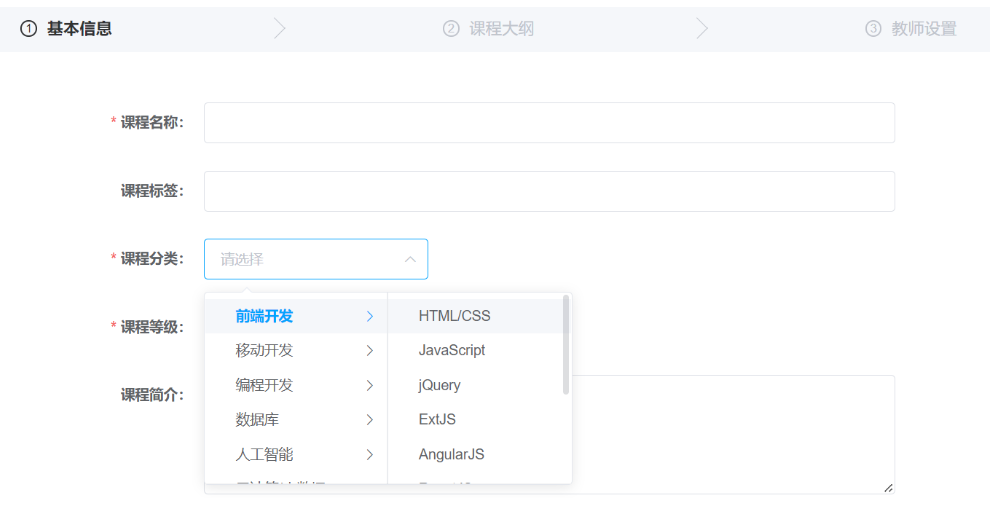

原图来源：第二章“4.4 接口测试”。

**怎么用**：看响应是否使用`childrenTreeNodes`，不要改成`children`却仍期待原前端自动识别。数据库节点 ID 看起来有层级，不应靠字符串截取推断父子，关系以`parentid`为准。


## 21. 树形查询：自连接与递归 CTE

树只有两层时可以用自连接；层数不确定时，MySQL 8 的递归查询能一次获取一个子树的所有节点。

**自连接**让同一张表以不同别名连接。讲义的两层查询用 INNER JOIN；没有子节点的父分类会被过滤。若需要保留空父分类，用 LEFT JOIN，并注意子表展示条件放到 ON 中，避免 WHERE 把它重新变成内连接。

**CTE**（公共表表达式）是单条 SQL 中的命名查询结果；`WITH RECURSIVE`允许后续步骤引用前一轮结果。原 Mapper 的核心：

```sql
WITH RECURSIVE t1 AS (
    SELECT * FROM course_category WHERE id = '1'
    UNION ALL
    SELECT child.*
    FROM course_category child
    INNER JOIN t1 ON t1.id = child.parentid
)
SELECT * FROM t1 ORDER BY t1.id;
```

| 组成 | 意义 |
|---|---|
| 初始查询 | 找到 ID 为`1`的起点 |
| 递归项 | 找到上一轮节点的孩子 |
| UNION ALL | 把每轮结果加入结果集，不主动去重 |
| 最终 SELECT | 输出根与所有后代的平面列表 |

向上找祖先则以叶子为起点，用`t1.parentid = parent.id`连接；方向取决于连接条件，不取决于最终 ORDER BY。

> MySQL 8 默认`cte_max_recursion_depth=1000`限制递归层数，不是总节点数。数据形成环可能持续递归，必须保证父子关系有效并控制规模；不能把递归 CTE 简单等同于存储过程，也不能认为“一次数据库调用”就一定性能好。

两种场景：固定两级分类可自连接；任意深度子树可递归 CTE。若 Java 对每个节点都发一次查询，会产生大量往返；先批量查询再在内存组装通常更容易控制调用次数。


## 22. 分类 Mapper 与 Map 组装树

递归 SQL 返回的是平面节点，前端需要嵌套数组，因此还要进行一次内存组装。

Mapper SQL 使用参数绑定：

```xml
<select id="selectTreeNodes"
        parameterType="string"
        resultType="com.xuecheng.content.model.dto.CourseCategoryTreeDto">
  WITH RECURSIVE t1 AS (
    SELECT * FROM course_category WHERE id = #{id}
    UNION ALL
    SELECT child.*
    FROM course_category child
    INNER JOIN t1 ON t1.id = child.parentid
  )
  SELECT * FROM t1 ORDER BY t1.id
</select>
```

`CourseCategoryTreeDto extends CourseCategory`，增加`List<CourseCategoryTreeDto> childrenTreeNodes`。原 Service 采用两遍处理：

| 步骤 | 操作 |
|---|---|
| 查询 | 一次取得根和后代 |
| 建索引 | 排除总根，将其他节点放入`Map<id, node>` |
| 找顶层 | `parentid==rootId`的节点加入返回列表 |
| 连孩子 | 按 parentid 找父对象，初始化其 childrenTreeNodes 后加入当前节点 |
| 返回 | 返回根的孩子列表，节点对象已经包含嵌套子树 |

先建完整 Map，所以即使某个孩子先被遍历，仍能找到父对象。Map 平均查找 O(1)，两遍组装平均 O(n)，再排序会增加排序成本。

**补充**：原 SQL 按 ID 排序，字典序可能把`1-1-10`放在`1-1-2`前面；需要业务顺序时，对每个同级列表按`orderby`并加 ID 作为次序规则排序。原递归 SQL也未按`is_show`过滤，应明确隐藏节点及其后代的展示规则。

**正例**：仅返回总根的直接孩子，每个孩子携带自己的后代。  
**反例**：直接把递归查询的所有节点平铺返回，或保留错误的父节点关系导致节点丢失。空树、无孩子节点和父节点缺失都应有明确处理。


## 23. 新增课程接口：一个表单、两张表

“保存并下一步”同时提交基本信息和营销信息，接口不能只写其中一张表。

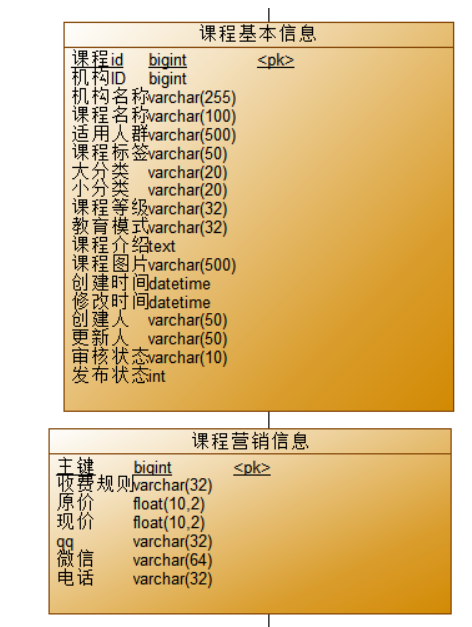

原图来源：第二章“5.1.2 数据模型”（原文小节编号写为 4.1.2）。

`POST /content/course`接收`AddCourseDto`，返回`CourseBaseInfoDto`。请求示例：

```http
POST http://localhost:63040/content/course
Content-Type: application/json

{
  "name": "Java 课程实践",
  "users": "具备 Java 基础的开发学习者",
  "mt": "1-1",
  "st": "1-1-1",
  "grade": "204001",
  "teachmode": "200002",
  "description": "通过实践理解课程开发流程",
  "pic": "",
  "tags": "Java",
  "charge": "201000",
  "price": 0,
  "originalPrice": 0,
  "qq": "",
  "wechat": "",
  "phone": "",
  "validDays": 365
}
```

分类及字典代码需以实际数据库为准。当天课程允许暂不处理课程图片上传，课程计划、师资和媒资也不由这个接口自动创建。

| 数据来源 | 字段 |
|---|---|
| 表单 | 名称、分类、等级、模式、适用人群、营销信息 |
| 后端身份上下文 | 所属机构 |
| 后端生成 | 课程 ID、创建时间 |
| 后端业务初始值 | `auditStatus=202002`、`status=203001` |

课程 Controller 临时硬编码`companyId=1232141425L`，因为认证系统尚未上线。实际接入认证后应从登录用户取得机构身份；AddCourseDto 不应允许客户端自行设定审核通过或已发布状态。


## 24. 参数校验与业务校验：表单通过后仍要检查什么

页面可以提示“请输入课程名”，但直接发送 HTTP 请求可以绕过页面，因此后端必须守住输入规则和业务规则。

**参数校验**检查格式、必填和范围；**业务校验**检查数据在当前业务中是否允许，例如分类存在、小类属于所选大类、机构有操作权限。

| 检查 | 当天原实现 | 完善时要考虑 |
|---|---|---|
| 名称、分类、等级、模式、适用人群 | Service 手写非空检查 | 字段长度、字典值有效性 |
| 收费规则 | 非空；`201001`走收费分支 | 仅允许实际字典支持的代码 |
| 收费价格 | `price==null`或`price<=0`报错 | 精度、上限、免费规则 |
| 大类和小类 | 只检查字符串不为空 | 分类是否存在、小类的 parentid 是否等于大类 ID |
| 机构 ID | Controller 临时固定一个 ID | 从可信登录身份取得，并验证权限 |

原代码名称和价格检查已经使用`XueChengPlusException.cast(...)`，其余部分仍抛`RuntimeException`。它们都会中断执行，但统一异常处理后，普通 RuntimeException 进入通用分支，页面得到的未必是具体业务提示。

`StringUtils.isBlank`识别 null、空串和纯空格；使用 Apache Commons Lang 的`org.apache.commons.lang3.StringUtils`，不要与其他库的同名类混用。

```java
// 原实现的名称检查
if (StringUtils.isBlank(dto.getName())) {
    XueChengPlusException.cast("课程名称为空");
}

// 原实现的收费检查（CourseMarket.price 当前为 Float）
if ("201001".equals(courseMarketNew.getCharge())) {
    if (courseMarketNew.getPrice() == null
            || courseMarketNew.getPrice().floatValue() <= 0) {
        XueChengPlusException.cast("课程的价格不能为空并且必须大于0");
    }
}
```

**正例**：先检查分类记录存在，再检查小类的父节点，最后进入保存。  
**反例**：`mt`和`st`非空就认定分类正确，或收费代码写成任意字符串却被当成免费。

> 当天代码包的 AddCourseDto 已预置校验注解，但 Controller 新增参数尚未添加`@Validated`。注解写在 DTO 上，不等于 HTTP 请求自动完成这些校验。JSR303 的触发、分组与异常处理在 day03 学习；本篇保留手写校验的执行过程。


## 25. 保存基本信息与营销信息：主键从哪里来

两张表描述同一门课程，必须用同一个课程 ID 关联，不能各自生成互不相关的主键。

`course_base.id`使用`@TableId(value="id", type=IdType.AUTO)`，由数据库生成自增主键，Mapper 插入后回填到实体。`course_market.id`使用同一个课程 ID，表达一对一营销信息。

| 顺序 | 操作 | 原因 |
|---|---|---|
| 1 | 校验请求与业务规则 | 阻止非法数据写入 |
| 2 | DTO → CourseBase，设置机构、时间和初始状态 | 用户输入与后端控制字段分开处理 |
| 3 | 插入 CourseBase，取得回填 ID | 确定课程身份 |
| 4 | DTO → CourseMarket，设置同一个 ID | 建立一对一关联 |
| 5 | 保存营销信息，检查写入结果 | 避免基本信息成功而营销未保存 |
| 6 | 查询并组装 CourseBaseInfoDto | 返回页面需要的完整信息 |

以下是**新增主流程的补全片段**。省略了第 24 节的参数和业务检查，保留原课程调用顺序，并补上 ID 与营销写入行数检查；放在已注入 Mapper 的 Service 实现中：

```java
@Transactional
@Override
public CourseBaseInfoDto createCourseBase(Long companyId, AddCourseDto dto) {
    // 此处先执行参数、分类、字典及机构等校验
    CourseBase base = new CourseBase();
    BeanUtils.copyProperties(dto, base);
    base.setCompanyId(companyId);
    base.setCreateDate(LocalDateTime.now());
    base.setAuditStatus("202002");
    base.setStatus("203001");

    int baseRows = courseBaseMapper.insert(base);
    if (baseRows <= 0 || base.getId() == null) {
        XueChengPlusException.cast("添加课程失败");
    }

    CourseMarket market = new CourseMarket();
    BeanUtils.copyProperties(dto, market);
    market.setId(base.getId());
    int marketRows = saveCourseMarket(market);
    if (marketRows <= 0) {
        XueChengPlusException.cast("保存课程营销信息失败");
    }
    return getCourseBaseInfo(base.getId());
}
```

**来源差异**：day02 代码包调用`saveCourseMarket`后没有检查其返回值；讲义完整示例包含失败检查。事务并不会因为 Mapper 返回 0 自动回滚，应把违反业务预期的结果转为异常。

`saveCourseMarket`先检查收费规则，再按课程 ID 查询：不存在就 insert，存在则复制输入后 updateById。这是课程抽出的复用方法；“先查后写”本身不能解决并发竞争，仍需数据库约束及明确的冲突处理。

**BeanUtils.copyProperties**按同名且类型兼容的属性复制，是浅拷贝：不会把字符串自动转为任意类型，不做校验或授权，也不会深复制嵌套对象。应使用`org.springframework.beans.BeanUtils`。

> 正例：拷贝表单后，后端明确设置机构和业务初始状态。反例：把任意前端字段直接复制到持久化对象，就允许客户端指定审核状态。DTO 限定可接收字段，后端赋值继续限定系统控制字段。


## 26. @Transactional：两张表必须一起成功

如果基本信息已经插入，营销价格随后校验失败，数据库不能留下半份课程。

**事务**把一组操作作为整体提交或回滚。本例两张表位于同一个内容服务数据源，属于**本地事务**。Spring 在公共 Service 方法上通过`@Transactional`管理它。

`Controller → Spring 代理 → 开启事务 → 基本信息插入 → 营销保存 → 组装结果 → 提交`

遇到符合回滚规则的异常时，流程变为：

`基本信息插入 → 营销校验 / 写入失败 → 异常离开 Service → 回滚 → 统一异常处理返回错误`

| 条件 / 误区 | 判断 |
|---|---|
| Controller 调用 Spring 管理的 Service bean | 经代理调用，事务可以生效 |
| 默认 RuntimeException / Error | 默认回滚 |
| 受检异常（checked exception） | 默认不一定回滚，按需求配置`rollbackFor` |
| private 保存方法没有注解 | 外层事务已经开启，其数据库操作仍可参与该事务 |
| 同类内直接调用另一个带注解的方法 | 通常绕过代理，不能期待它的新事务规则自动生效 |
| 捕获失败并返回成功 | 外层可能正常提交，破坏整体失败语义 |
| 两个服务各自写库 | 不能靠这里的本地注解直接解决跨服务原子性 |

**怎么验证**：在测试环境发送收费课程且价格为 0 的请求。原保存顺序是先插基本信息，再在营销方法检查价格，因此应进入回滚分支。检查响应，再查询两张表：本次课程均不应留下记录。若把价格校验提前到所有插入之前，需要用受控的第二次写入失败来验证回滚。

**反例**：

```java
// 示意：异常被吞掉，事务方法可能正常结束并提交
try {
    saveCourseMarket(market);
} catch (RuntimeException e) {
    log.error("营销保存失败", e);
}
// 继续返回“成功”，基本信息可能已经提交
```

> `@Transactional`不会自动防止用户重复点击“保存”。防重复涉及按钮状态、业务唯一约束及幂等设计，不能把一次事务中的原子性当成多次请求的唯一性。

统一异常处理位于业务事务外层，把失败变为 HTTP 响应；它不替代回滚。也不要用“收到 500”代替检查数据库的实际结果。


## 27. 返回 CourseBaseInfoDto：聚合查询与金额类型

保存完成后，页面需要课程 ID、基本信息、营销信息和分类名称。一张 PO 不足以表达这个结果。

**聚合 DTO**按接口用途组合多种数据。本例`CourseBaseInfoDto extends CourseBase`，增加营销属性和`mtName / stName`，由`getCourseBaseInfo(courseId)`组装。

| 步骤 | day02 代码包行为 |
|---|---|
| 查基本信息 | 查不到返回 null |
| 查营销信息 | 根据相同课程 ID 查询 |
| 拷贝基本信息 | CourseBase → CourseBaseInfoDto |
| 拷贝营销信息 | 营销不为 null 时继续复制 |
| 设置分类名称 | 仍为 TODO；讲义完整示例另查分类并设置名称 |

**分类名称补全思路**：根据`mt / st`查询分类记录，检查存在及父子归属后设置`mtName / stName`。不能对可能为空的查询结果直接调用`getName()`。如果新增后必须返回完整对象，出现主记录或必需营销记录缺失时，应抛业务异常，不能以 null 冒充成功。

复制顺序也有意义：同名属性可能被后一次复制覆盖。这里两个实体的 ID 理应一致；当模型增加同名字段时，应重新检查聚合规则。

**金额类型补充**：原 AddCourseDto、CourseMarket 和 CourseBaseInfoDto 的价格字段实际为`Float`，即使源文件出现未使用的 BigDecimal import，也不能据此认定已经用十进制类型。

| 类型 | 用途与注意点 |
|---|---|
| Float / Double | 二进制浮点，部分十进制金额不能精确表示 |
| BigDecimal | 按十进制精度计算，需明确小数位及舍入规则 |
| 数据库 DECIMAL | 存储十进制金额，精度和小数位要与业务一致 |

实际金额设计应统一 DTO、PO、数据库字段和计算方式；不能只把一个 Java 字段改成 BigDecimal，却继续通过 Float 传递或计算价格。创建十进制常量优先使用字符串，例如`new BigDecimal("99.90")`。


## 28. 自定义异常、错误枚举与错误响应

所有失败都返回“系统异常”，用户难以修正输入；直接返回底层异常全文，又会把数据库和实现细节暴露给页面。

课程使用三种对象区分业务失败与 HTTP 错误数据：

| 对象 | 职责 |
|---|---|
| `XueChengPlusException` | 表达可向用户说明的业务失败，继承 RuntimeException |
| `CommonError` | 集中维护通用错误提示枚举 |
| `RestErrorResponse` | HTTP 错误响应体，当前只有`errMessage` |

原课程异常类的核心结构：

```java
public class XueChengPlusException extends RuntimeException {
    private String errMessage;

    public XueChengPlusException(String message) {
        super(message);
        this.errMessage = message;
    }

    public String getErrMessage() {
        return errMessage;
    }

    public static void cast(String message) {
        throw new XueChengPlusException(message);
    }

    public static void cast(CommonError error) {
        throw new XueChengPlusException(error.getErrMessage());
    }
}
```

`cast`是课程的“抛出异常”辅助方法，并非 Java 类型强制转换，也不会正常返回。构造器的`super(message)`把信息交给父类，`getMessage()`和日志因此能取到消息。

| CommonError 原枚举名 | 提示 |
|---|---|
| `UNKOWN_ERROR` | 执行过程异常，请重试。 |
| `PARAMS_ERROR` | 非法参数 |
| `OBJECT_NULL` | 对象为空 |
| `QUERY_NULL` | 查询结果为空 |
| `REQUEST_NULL` | 请求参数为空 |

`UNKOWN_ERROR`是源代码的原拼写，引用时须一致。讲义异常包出现`execption`误拼，实际代码使用`com.xuecheng.base.exception`。

业务失败响应示例：

```json
{
  "errMessage": "课程的价格不能为空并且必须大于0"
}
```

**怎么用**：能解释给用户的失败抛业务异常；未知程序错误记录服务日志，对外返回通用提示。不要把所有 RuntimeException 都直接显示其 message，也不要捕获失败后包装成成功数据。


## 29. 统一异常处理：业务失败怎样到达前端

每个 Controller 都写 try/catch 会重复代码，也容易出现响应格式不一致。统一处理让前端按固定字段读取错误。

**`@ControllerAdvice`**在 Spring MVC 控制器范围内提供公共处理；`@ExceptionHandler`匹配异常；`@ResponseBody`将返回对象序列化；`@ResponseStatus`指定 HTTP 状态。

以下保留课程的 **500 状态约定**，日志文案稍作区分：

```java
@Slf4j
@ControllerAdvice
public class GlobalExceptionHandler {
    @ResponseBody
    @ExceptionHandler(XueChengPlusException.class)
    @ResponseStatus(HttpStatus.INTERNAL_SERVER_ERROR)
    public RestErrorResponse customException(XueChengPlusException e) {
        log.error("业务异常：{}", e.getErrMessage(), e);
        return new RestErrorResponse(e.getErrMessage());
    }

    @ResponseBody
    @ExceptionHandler(Exception.class)
    @ResponseStatus(HttpStatus.INTERNAL_SERVER_ERROR)
    public RestErrorResponse exception(Exception e) {
        log.error("未预期异常：{}", e.getMessage(), e);
        return new RestErrorResponse(CommonError.UNKOWN_ERROR.getErrMessage());
    }
}
```

业务异常进入专门处理器，其他 Exception 进入通用处理器。日志保留异常对象以记录堆栈；返回体只包含适合页面显示的信息。该类放在 base 工程后，还要确认 API 应用依赖 base，并扫描到所在包。

`@RestControllerAdvice`在此用途下等价于`@ControllerAdvice + @ResponseBody`。它处理 MVC 请求链异常，不会自动接管线程池、定时任务或所有后台线程异常。

| HTTP 语义补充 | 常见状态 |
|---|---|
| 参数格式 / 业务输入不合法 | 400 / 422，按接口规范选择 |
| 未认证 / 无权限 | 401 / 403 |
| 资源不存在 / 状态冲突 | 404 / 409 |
| 未预期服务错误 | 500 |

**课程与一般规则要分清**：原课程业务异常和未知异常均返回 500，前端按该契约显示`errMessage`。如果改用更具体的状态码，后端与前端错误处理须一起调整。一般接口成功可使用 2xx，不能把“所有非 200 都失败”当成通用规则，201、204 也可能是正常成功。

通用`Exception`处理器还可能把 JSON 绑定等协议异常统一改成 500。完善时应为这类异常保留专门处理，而不是因为有统一处理就忽略原 HTTP 语义。day03 再加入参数校验异常分支。


## 30. 复现时对照：资料、代码和补全内容

课程资料给出开发过程，代码包也保留部分待完成点。遇到“按讲义写了但结果不同”，先对照当前文件与版本。

| 位置 | 已核对的情况 | 本篇处理 |
|---|---|---|
| 父工程 | Boot`2.3.7.RELEASE`、Cloud`Hoxton.SR9`、Alibaba`2.2.6.RELEASE` | 沿用当天代码基线 |
| 持久层 | MyBatis-Plus`3.4.1`、MySQL 驱动`8.0.30` | 使用该版本分页拦截器；递归 CTE 需要 MySQL 8 |
| 接口文档 | `swagger-spring-boot-starter 1.9.0.RELEASE` | 文档描述不等于参数校验 |
| 数据库连接 | 代码使用`xc402_content / xc402_system` | 按自己实际导入的库名核对 |
| 查询 body | 可不传 body，但原 Service 直接解引用 | 补默认查询对象 |
| 发布状态 | 原 Service 留 TODO | 给出等值筛选补全 |
| 机构与排序 | 原列表查询没有机构过滤及稳定排序 | 说明可信机构条件和双字段排序 |
| 状态代码 | 审核字典片段与`202004`请求样例不一致 | 要求按真实字典确认 |
| HTTP 变量 | 原文字样例遗漏协议 | 统一使用完整主机 URL |
| CORS | 代码类在 system，通配来源与凭据并用 | 以实际调用服务和具体来源配置 |
| 分类树 | SQL 按 ID 排序，未按展示标记过滤 | 标明业务顺序与隐藏节点规则 |
| 新增营销 | 代码没检查保存返回行数 | 给出失败检查 |
| 聚合返回 | 分类名称仍 TODO | 给出补全步骤与空值检查 |
| 参数注解 | DTO 有注解，Controller 尚未触发验证 | day03 展开 |
| 异常 | 业务和未知异常都用 500 | 保留课程契约，另列 HTTP 语义补充 |

本篇的补全是学习建议，未修改或重新打包网盘源码。示例中的注入对象、模型及 import 应从相应工程引入，不能把 Markdown 片段单独当成已验证可运行项目。


## 31. 当天验收与资料覆盖

学完后的目标是四个接口可以独立调用，并能在页面完成查询和新增。以下是**自行复现时的验收清单**，不表示本笔记已执行这些测试。

| 场景 | 预期结果 / 检查点 |
|---|---|
| 无筛选分页 |`items / counts / page / pageSize`对应；无数据也返回合理空列表 |
| 名称、审核、发布组合 | 条件同时生效，未填写的条件不拼接 |
| 第一页与末页 | 页大小正确，总数正确，同值记录有稳定次序 |
| 查询 body 缺省 /`{}` | 按接口约定处理，不出现空指针 |
| 非法页码 / 页大小 | 明确拒绝或规范化，限制单页上限 |
| 机构隔离补全 | 用户无法查到其他机构课程 |
| 数据字典 | code 与页面文案对应；请求真正到 system |
| 分类树 | 不含虚拟总根，孩子嵌套正确，孤立节点规则明确 |
| 免费课程新增 | 两表成功，ID 相同，机构与初始状态由后端设置 |
| 收费且价格有效 | 保存金额及收费代码，返回完整信息 |
| 名称为空 / 分类无效 | 返回明确错误，不插入非法课程 |
| 第二次写入失败 | 整体回滚，两表无本次残留；日志能定位错误 |
| 业务 / 未知异常 | 统一`errMessage`；未知错误不回传底层细节 |
| 浏览器联调 | URL、payload、OPTIONS、响应及页面展示一致 |

**资料覆盖定位**：

| 原讲义范围 | 本篇章节 |
|---|---|
| 1 内容管理模块需求分析 | 1—2 |
| 2 内容管理模块工程搭建 | 3—5、11 |
| 3 课程查询与联调 | 6—19 |
| 4 课程分类查询 | 20—22 |
| 5 新增课程至 5.6 异常处理 | 23—29 |
| 5.7 JSR303、修改课程、课程计划 | 按 14 天目录归入 day03 |
| 内容管理实战 | 按目录归入 day04 |

本篇已静态核对讲义、day02 代码包的 11 个 POM、相关 Java / Mapper / HTTP 文件，并将 5 张讲义原图作为 Notebook 附件。生成时检查 Notebook 结构、代码围栏、JSON / YAML / XML 格式、附件可解码与来源哈希。**未编译、启动课程服务，未执行 SQL 或验证运行结果。**


## 32. 面试提示

**面试提示**：

| 常见问题 | 回答要点 |
|---|---|
| 为什么课程列表用 POST 查询？ | 查询条件放 JSON body，分页放 URL 参数；HTTP 方法由接口契约决定，查询本身不应产生写入副作用 |
| MyBatis-Plus 如何分页？ | IPage / Page 传递页信息，分页拦截器处理查询和 count；返回记录与总数，页码从 1 开始 |
| DTO、PO、VO 有什么区别？ | DTO 按数据传输用途组织，PO 对应持久化，VO 按展示用途组织；命名与实际职责要一致 |
| 为什么新增要用两张表？ | 基本与营销信息分开建模，使用相同课程 ID 关联；一次新增应保证完整性 |
| 为什么 BeanUtils 不能代替校验？ | 只复制同名兼容属性，不验证值、权限或业务规则，浅拷贝也不保证对象隔离 |
| 事务什么时候回滚？ | 经 Spring 代理开启事务，异常符合回滚规则且没有被吞；默认 RuntimeException / Error 回滚 |
| Mapper 返回 0 会回滚吗？ | 不会仅因为行数为 0 回滚；违反业务预期时显式抛出异常 |
| 如何返回分类树？ | 自连接 / 递归 CTE 获取平面节点，再以 Map 按 parentid 组树；确认根、排序与空节点规则 |
| 为什么 HTTP Client 成功，浏览器失败？ | 浏览器还执行同源 / CORS 规则；核对 Origin、预检和响应头，以及实际请求路径 |
| 统一异常处理有什么用？ | 集中生成错误响应并记录堆栈，区分可展示业务提示和未知错误；不代替事务和授权 |
| 原课程还有哪些待完善点？ | 发布筛选、机构隔离、分类名称、营销行数检查、校验触发及细化 HTTP 错误语义 |

尝试用一个完整场景串起答案：机构老师提交课程 → 后端验证输入与身份 → 在一个本地事务中写两表 → 组装 DTO → 页面收到成功或统一错误。说明自己核对到的代码行为、补全建议和待运行验证的部分，比只背注解名称更有用。
